# P7.13 — Rejeita-faixa de comprimento mínimo com janela de Kaiser

**Referência:** Ingle & Proakis, *DSP Using MATLAB*, 3ª ed., p. 379 · DTA §2.1 (item 5), §3.1.D e §4 (Resolução P7.13).

> *Using the Kaiser window method, design a linear-phase FIR digital filter that meets the following specifications: 0.975 ≤ |H(e^{jω})| ≤ 1.025, 0 ≤ ω ≤ 0.25π; 0 ≤ |H(e^{jω})| ≤ 0.005, 0.35π ≤ ω ≤ 0.65π; 0.975 ≤ |H(e^{jω})| ≤ 1.025, 0.75π ≤ ω ≤ π. Determine the minimum length impulse response h(n) of such a filter. Provide a plot containing subplots of the amplitude response and the magnitude response in dB. Do not use the fir1 function.*

| Faixa | Ganho ideal | Tolerância |
|---|---|---|
| $0 \le \omega \le 0.25\pi$ | 1 | $\delta_1 = 0.025$ |
| $0.35\pi \le \omega \le 0.65\pi$ | 0 | $\delta_2 = 0.005$ |
| $0.75\pi \le \omega \le \pi$ | 1 | $\delta_1 = 0.025$ |

In [1]:
# Configuração do ambiente (local ou Google Colab)
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # No Colab, disponibilize o projeto em PROJECT_DIR antes de executar:
    #   (a) Arquivos → upload de dsp-avaliacao-2.zip e  !unzip -q dsp-avaliacao-2.zip
    #   (b) ou monte o Drive:  from google.colab import drive; drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/dsp-avaliacao-2")
    %pip install -q -r {PROJECT_DIR}/requirements.txt
else:
    PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

for p in (PROJECT_DIR, PROJECT_DIR / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("Projeto em:", PROJECT_DIR)

Projeto em: /mnt/storage/projects/dsp-avaliacao-2


## 1. Método de Kaiser

A janela de Kaiser tem um parâmetro de forma $\beta$ que controla a altura dos lóbulos laterais, e com ela a atenuação. Fórmulas empíricas de Kaiser dão $\beta$ e uma **estimativa** de $M$.

**Tolerância de projeto.** No método da janela, as ondulações de passagem e de rejeição saem aproximadamente iguais. Projeta-se então pela menor delas:

$$\delta = \min(\delta_1, \delta_2) = 0.005 \quad\Rightarrow\quad A_s = -20\log_{10}\delta = 46.02\ \text{dB}$$

**Parâmetro de forma** ($21 < A_s < 50$):

$$\beta = 0.5842(A_s - 21)^{0.4} + 0.07886(A_s - 21) = 4.0909$$

**Estimativa do comprimento**, com $\Delta\omega = 0.35\pi - 0.25\pi = 0.1\pi$:

$$M \approx \left\lceil \frac{A_s - 7.95}{2.285\,\Delta\omega} \right\rceil + 1 = \lceil 53.03 \rceil + 1 = 55$$

**Paridade e cortes.** O rejeita-faixa exige M ímpar (Tipo 1), e 55 já é ímpar. Cortes: $\omega_{c1} = 0.3\pi$, $\omega_{c2} = 0.7\pi$.

$$h(n) = \left\{\delta(n-\alpha) - \frac{\sin[\omega_{c2}(n-\alpha)] - \sin[\omega_{c1}(n-\alpha)]}{\pi(n-\alpha)}\right\} \frac{I_0\left(\beta\sqrt{1-\left(\frac{2n}{M-1}-1\right)^2}\right)}{I_0(\beta)}$$

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from dsp_av2.fir import analysis
from dsp_av2.specs import P7_13 as SPEC
from exercises import p7_13

e = p7_13.estimate()
print(f"A_s = {e.params['As_design_dB']:.4f} dB,  β = {e.params['beta']:.4f}")
print(f"Δω = {e.transition_width:g}π,  ωc = {e.cutoffs[0]:g}π e {e.cutoffs[1]:g}π")
print(f"Estimativa de Kaiser: M = {e.M}\n")
print(p7_13.validate(e))

A_s = 46.0206 dB,  β = 4.0909
Δω = 0.1π,  ωc = 0.3π e 0.7π
Estimativa de Kaiser: M = 55

Validação P7.13 (Tipo 1 de fase linear)
  [OK  ] ||H| − 1| em [0π, 0.25π]: 0.0052 <= 0.0250  (folga +0.0198)
  [FALHA] ||H| − 0| em [0.35π, 0.65π]: 0.0059 <= 0.0050  (folga -0.0009)
  [OK  ] ||H| − 1| em [0.75π, 1π]: 0.0052 <= 0.0250  (folga +0.0198)
  Resultado: NÃO ATENDE


## 2. A estimativa **não** atende: busca do comprimento mínimo

Com $M = 55$, a magnitude na rejeição chega a ≈ 0.0059, acima do limite de 0.005. A fórmula de Kaiser é empírica (um ajuste de curvas) e pode errar em ±1–2 amostras.

O enunciado pede o **comprimento mínimo**, então a resposta precisa ser verificada (decisão D2 do plano). Mantendo $\beta$ fixo, testam-se os comprimentos ímpares em ordem crescente, e o primeiro que atende às três tolerâncias é o mínimo:

In [3]:
s = p7_13.search()
from dsp_av2.fir.design import design_kaiser
from dsp_av2.validation import validate_fir_tolerance

print(" M    desvio passagem   max|H| rejeição   atende?")
for M, ok in s.tried[-5:]:
    r = validate_fir_tolerance(design_kaiser(SPEC, M=M))
    print(f"{M:3d}       {r.checks[0].measured:.5f}          {r.checks[1].measured:.5f}        {'sim' if ok else 'não'}")
print(f"\nComprimento mínimo verificado: M = {s.M_min}")

 M    desvio passagem   max|H| rejeição   atende?
 49       0.01823          0.01734        não
 51       0.01237          0.01098        não
 53       0.00714          0.00747        não
 55       0.00515          0.00593        não
 57       0.00390          0.00367        sim

Comprimento mínimo verificado: M = 57


## 3. Resultados

Pedidos: subplots da resposta de amplitude $H_r(\omega)$ e da magnitude em dB. A resposta ao impulso aparece no topo como contexto. Em $H_r(\omega)$, as linhas tracejadas marcam as faixas de tolerância $G \pm \delta$.

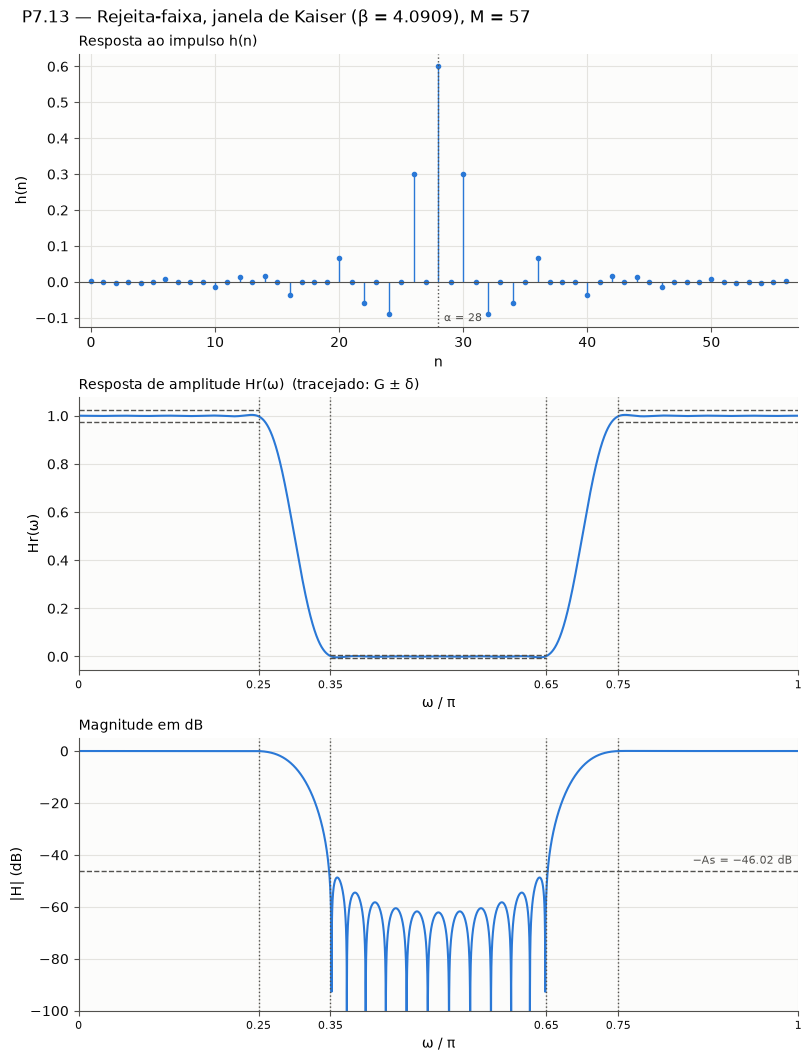

In [4]:
d = s.best
fig = p7_13.plot(d)
plt.show()

## 4. Validação contra a especificação

In [5]:
print(validate_fir_tolerance(d, n_points=200001))

Validação P7.13 (Tipo 1 de fase linear)
  [OK  ] ||H| − 1| em [0π, 0.25π]: 0.0039 <= 0.0250  (folga +0.0211)
  [OK  ] ||H| − 0| em [0.35π, 0.65π]: 0.0037 <= 0.0050  (folga +0.0013)
  [OK  ] ||H| − 1| em [0.75π, 1π]: 0.0039 <= 0.0250  (folga +0.0211)
  Resultado: ATENDE à especificação


**Observação.** A tolerância da passagem ($\delta_1 = 0.025$) fica muito folgada: o desvio medido é ≈ 0.004, porque o método da janela iguala as ondulações das duas faixas e quem limita é $\delta_2$. Métodos que ponderam as faixas separadamente (Parks-McClellan, Seção 7.6) aproveitam essa folga e obtêm filtros mais curtos. O P7.15 faz essa comparação.

## 5. Conclusão

- Kaiser: $A_s = 46.02$ dB e $\beta = 4.0909$, valores que coincidem com o DTA.
- A estimativa empírica $M = 55$ (o valor do DTA) **viola** a especificação: $\max|H| \approx 0.0059 > 0.005$ na rejeição.
- O comprimento mínimo verificado é **$M = 57$** (Tipo 1, $\alpha = 28$): desvio ≈ 0.0039 na passagem e $\max|H| \approx 0.0037$ na rejeição.
- O caso mostra a regra metodológica do projeto: fórmulas de projeto dão estimativas, e o resultado só vale depois de medido.